# Prosjekt 3 Alfred og Gaute

In [233]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import inv
from scipy.integrate import solve_bvp
from tqdm import trange
from scipy.integrate import simpson

I = np.identity(2)

## Oppgave 1

### 1a)
$\frac{\partial^2y}{\partial x^2} = -4\cdot sin(2x),\ y(0)=0,\  y'(0)=2$

Siden høyresiden ikke avhenger av y, kan vi integrere begge sider. det blir:

$\frac{\partial y}{\partial x} = 2\cdot cos(2x)+A,\ y(0)=0,\  y'(0)=2$

Innsatt initialbetingelsen for $y'$ får vi:

$\frac{\partial y}{\partial x} = 2\cdot cos(2x),\ y(0)=0$

Igjen avhenger ikke høyresiden av y, så kan integrere.

$y(x) = sin(2x) + B,\ y(0)=0$

Innsatt initialbetingelsen for y.

$y(x) = sin(2x)$

### 1b)
Definerer:

$\vec{y} = \left( \begin{matrix} y_1 \\ y_2 \end{matrix} \right) = \left( \begin{matrix} y \\ y' \end{matrix} \right)$

Da blir differensialligningen:

$\vec{y}' = \left( \begin{matrix} y_1' \\ y_2' \end{matrix} \right) = \left( \begin{matrix} y' \\ y'' \end{matrix} \right) = \left( \begin{matrix} y_2 \\ -4sin(2x) \end{matrix} \right)$

Og initialbetingelsen blir:

$\vec{y}(0) = \left( \begin{matrix} y(0) \\ y'(0) \end{matrix} \right) = \left( \begin{matrix} 0 \\ 2 \end{matrix} \right)$


### 1c)

Implementerer rungekutta som beskrever i prosjektbeskrivelsen

In [234]:
def RungeKutta32(
        x_init : float,
        x_end : float,
        y_init : np.ndarray[np.float64],
        f,
        h0 : float =0.1,
        tol : float = 1e-7,
        alpha : float = 0.8
                 ) -> tuple:
    
    # Vil bruke numpy array så gjør et gjett på størrelsen til x
    x  =  np.zeros(int(np.ceil((x_end-x_init)/h0)))
    y  =  np.zeros((int(x.size),len(y_init)))
    h  =  np.zeros_like(x)
    
    # Bruker intialbetingelsene for første iterasjon
    h[0] = h0
    x[0] = x_init
    y[0] = y_init
    z    = 0
    n    = 0
    m    = 0
    k1   = f(x_init,y_init)

    while x_end-x[n] > 0:
       
        # Gjør arrayet større i tilfellet at gjetningen på størreslen var for liten
        if len(x)==n+1:
            sizeInc = int(np.ceil((x_end-x[n])/h[n]))
            x = np.concatenate((x,np.zeros(sizeInc)))
            y = np.concatenate((y,np.zeros((sizeInc,len(y_init)))))
            h = np.concatenate((h,np.zeros(sizeInc)))

        
        h[n] = min(h[n],x_end-x[n]) # Sørger for at den treffer slutt verdien til x

        # Gjør en iterasjon av rungekutta
        k2 = f(x[n]+h[n]/2,y[n]+h[n]*k1/2)
        k3 = f(x[n]+3/4*h[n],y[n]+3/4*h[n]*k2)
        y[n+1] = (y[n]+h[n]/9*(2*k1+3*k2+4*k3))
        x[n+1] = (x[n]+h[n])
        k4 = f(x[n]+h[n],y[n+1])
        z = y[n]+h[n]/24*(7*k1+6*k2+8*k3+3*k4)
        err_est = np.linalg.norm(y[n+1]-z)
        if err_est<tol:
            h[n+1]=alpha*h[n]*(tol/err_est)**(1/3)
            n += 1
            k1 = k4
        else:
            h[n]=alpha*h[n]*(tol/err_est)**(1/3)
            m+=1
        
    
    # Fjerner nuller bakerst i arrayet i tilfellet array ble for stort
    x = np.trim_zeros(x,trim="b")
    y = np.trim_zeros(y,trim="b")
    h = np.trim_zeros(h,trim="b")


    return x, y, (n,h,m)

Definerer høyresiden av differensialligningen på formen funnet i 1b

In [235]:
def diff_func_1a(
        x : float,
        y : np.ndarray[np.float64]
    )  -> np.ndarray[np.float64]:

    out=np.zeros_like(y)

    out[0]=y[1]
    out[1]=-4*np.sin(2*x)

    return out

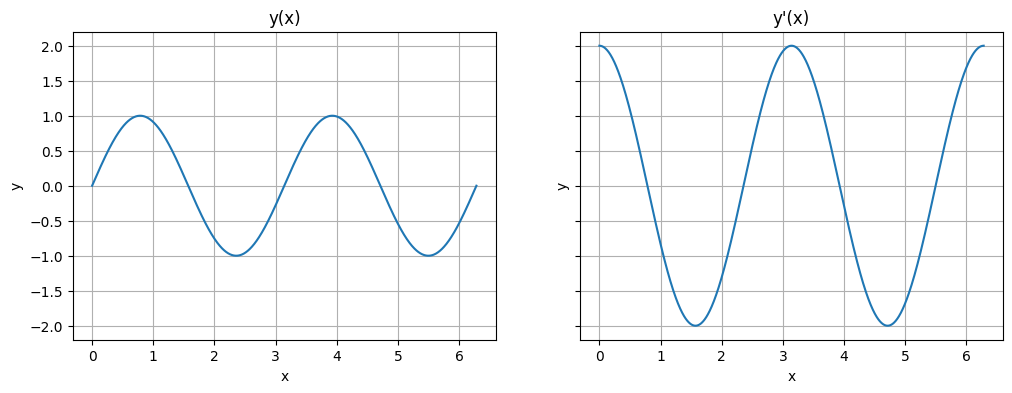

In [ ]:
x_init_c = 0
x_end_c  = 2*np.pi
y_init_c = np.array([0,2])


x , y , n = RungeKutta32(x_init_c,x_end_c,y_init_c,diff_func_1a,tol= 1e-7, alpha=0.8)


fig = plt.figure("Oppgave 1c", figsize=(12,4))
subplots = fig.subplots(1,2, sharey=True)
subplots[0].plot(x,y[:,0])
subplots[0].grid()
subplots[0].set_xlabel('x')
subplots[0].set_ylabel('y')
subplots[0].set_title('y(x)')

subplots[1].plot(x,y[:,1])
subplots[1].grid()
subplots[1].set_xlabel('x')
subplots[1].set_ylabel('y')
subplots[1].set_title("y'(x)")

plt.show()

Til venstre er løsningen av differensialligningen løst med rungekutta metoden. Den passer bra med den analytiske løsningen av differensialligningen som ble funnet i oppgave 1a, der grafen ligner helt på en $\pi$-periodisk sinus funksjon med amplitude lik 1. Til høyre er den deriverte av løsningen plottet. Den passer også med den analytiske løsningen. 

1070


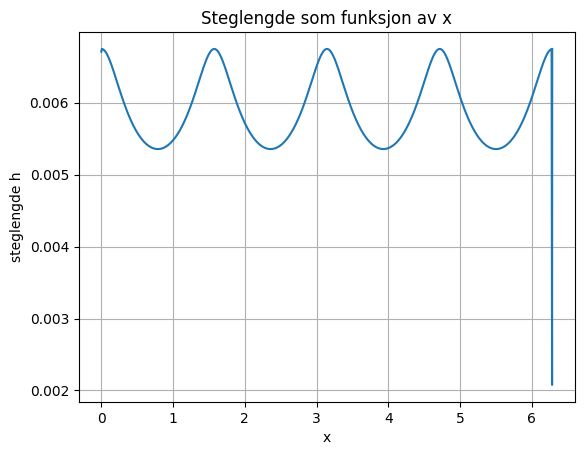

In [237]:
print(n[0])
plt.title("Steglengde som funksjon av x")
plt.plot(x,n[1])
plt.grid()
plt.xlabel("x")
plt.ylabel("steglengde h")
plt.show()

Over er plottet av steglengde som funksjon x-verdien. Som man kan se er steglengden høyest ved nullpunktene til funksjonen. Dette gir veldig mening ettersom det er der en sinus funksjon er mest linær, eller med andre ord der den dobbelt derivert er nærmest null. Tilsvarende er steglengden lavest ved ekstremalpunktene til løsningenen, siden det er der absolutverdien av den dobbeltderiverte er høyest. Steglengden sin avhengighet av den dobbelt deriverte kommer fra at rungekutta metoden gjør linære gjett, slik at hvis den dobbelt deriverte er høy vil feilen i et steg bli høyerere, og metoden vil derfor velge en lavere steglengde. Fallet i slutten av grafen kommer fra miniumsleddet i koden som sørger for at den siste h-verdien treffer på $x_{end}$


In [238]:
def anal_solution(x):
    return np.sin(2*x)


In [275]:
tols= np.logspace(1,-10,100)
error= np.zeros_like(tols)


for i in range(len(tols)):
    x , y , n= RungeKutta32(x_init_c,x_end_c,y_init_c,diff_func_1a,tol = tols[i], alpha=0.8)
    
    error[i] = np.linalg.norm(y[:,0]-anal_solution(x),1)/len(x)

Kjører rungekutta for flere verdier av toleransen, og plotter feilen som en funksjon av toleransen. Bruker 2-normen av differansen mellom analytisk og numersik løsning som feilestimat.

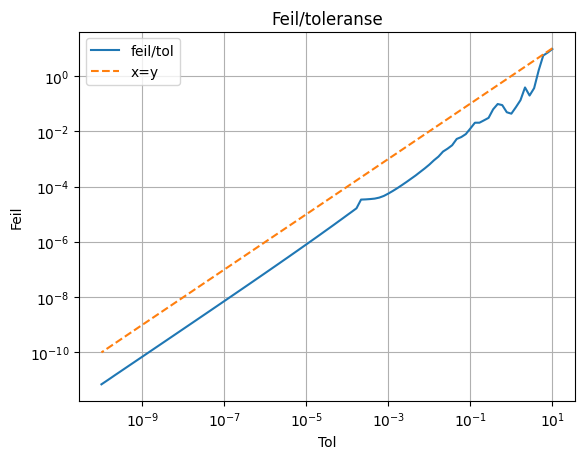

In [276]:
plt.figure("Error/tols")
plt.title("Feil/toleranse")
plt.grid()
plt.plot(tols,error, label= "feil/tol")
lin = np.logspace(1,-10,100)
plt.plot(lin,lin,"--", label= "x=y")
plt.xscale("log")
plt.yscale("log")
plt.ylabel("Feil")
plt.xlabel("Tol")
plt.legend()
plt.show()

Plottet viser feilen i hele løsningen over satt toleranse. Plottet er et log/log plott. I log/log plottet ser sammenhengen mellom toleransen og feilen ut til å være linær. Det betyr at sammenhengen i realiteten er polynomisk. 

For tilstrekklige 

In [277]:
alphas= np.linspace(0.1,1,100)
alphas[-1]=1
Iterations = np.zeros_like(alphas)
for i in range(len(alphas)):
    x , y , n= RungeKutta32(x_init,x_end,y_init,diff_func_1a, alpha=alphas[i])
    Iterations[i] = n[0]+ n[2]

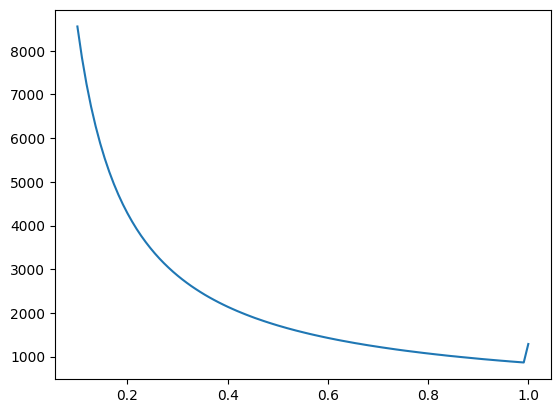

In [278]:
plt.figure("Iterations/alphas")
plt.plot(alphas, Iterations)
plt.show()

For fast steglengde vil antall iterasjoner være omvendt propsjonal med steglengden. Siden alfa er proposjonal med steglengden i hvert steg vil sammenhengen mellom alfa og antall godkjente iterasjoner også være omvendt propsjonal. Dette gjenspeiles godt i simulation der grafen ligner en rasjonal funksjon. For lave alfa er antall forkastede iterasjoner svært lite i forhold til antall godkjente iterasjoner slik at at en bare ser effekten av den omvendte proposjonaliteten. Derimot for alfa som nærmer seg 1 vil antall forkastede iterasjoner øke drastisk, som observert på grafen. Dette er fordi ved høye alfa vil feilen alltid være i næreheten av toleranse grensen, slik at det skal lite til før et steg blir forkastet. Alpha lik 1 er altså dårlig for effektiviten til programmet, men samtidig vil det være gunstig å ha så høy alfa som mulig. 

### 1e

Implementerer sekant metoden

In [243]:
def sekantMetode(
        g, 
        z0 : float,
        z1 : float,
        tol : float,
) -> float:
    z = [z0,z1]
    i=1
    while abs(z[i]-z[i-1])>tol:
        z_new=(z[i-1]*g(z[i])-z[i]*g(z[i-1]))/(g(z[i])-g(z[i-1]))
        z.append(z_new)
        i+=1
    return z


Definerer funskjon og kjører sekant metoden på den.

[10000, 100000000, np.float64(1.2579523548052556), np.float64(-1.2592279680193), np.float64(-0.1750218122707619), np.float64(-0.44630638988516436), np.float64(-0.4570006334566943), np.float64(-0.4566243218014748)]


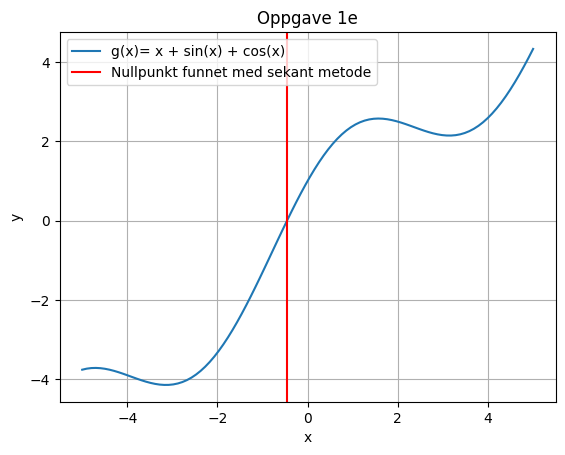

In [244]:
def test_g(x):
    return x + np.sin(x) + np.cos(x)

root = sekantMetode(test_g,10000,100000000,0.001)
print(root)
x=np.linspace(-5,5,100)
plt.figure("oppgave 1e")
plt.title("Oppgave 1e")
plt.plot(x,test_g(x), label = "g(x)= x + sin(x) + cos(x)")
plt.axvline(root[-1],0,1,color="r", label= "Nullpunkt funnet med sekant metode")
plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.legend()
plt.show()

Den blå grafen er et plot av funksjon, og den røde linjen er nullpunktet funnet av sekantmetoden. Sekant metoden treffer bra.

### 1f

Starter med å implementere skyte metoden. 

In [245]:
def BVP_solver(
        f,
        x_init : float,
        x_end : float,
        y_boundaries : tuple,
        b0 : float,
        b1 : float,
        tol : float = 1e-7,
) -> tuple:
    
    # Definerer først en funksjon som passer på formen til sekant metode løseren
    def rungef(b,x_init=x_init,x_end=x_end,y_boundaries=y_boundaries,f=f):
        y_init=np.array((y_boundaries[0],b))
        x,y,n = RungeKutta32(x_init,x_end,y_init,f,tol=tol)
        return y[:,0][-1]-y_boundaries[1] # Returnerer her differansen mellom y(x_end) for et gjett og grensebetingelsen til bvp
                                          # Dette blir null ved riktig gjett på initial betingelsen, så derfor kan sekant metoden løse for nullpunktet
    
    b_iterations = sekantMetode(rungef,b0,b1,tol) # Kjører sekant metoden på den nylig definerte funksjonen 
    y_init = np.array((y_boundaries[0],b_iterations[-1]))
    x,y,n = RungeKutta32(x_init,x_end,y_init,f,tol=tol)
    return x,y,n, b_iterations # Returnere siste iterasjon av y pluss et array med de forskjellig gjettene på initial betingelsen


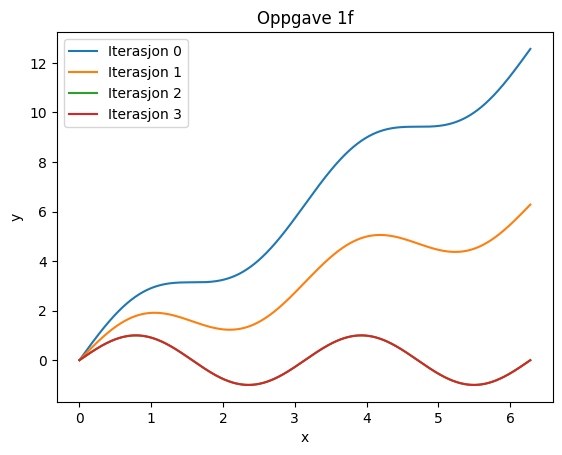

In [246]:
y_boundaries=(0,0)
b0=4
b1=3


result = BVP_solver(diff_func_1a,x_init_c,x_end_c,y_boundaries,b0,b1)

plt.figure("BVP solution 1f")
for i in range(len(result[3])):  
    y_init_f=np.array((y_boundaries[0],result[3][i]))
    x,y,n = RungeKutta32(x_init_c,x_end_c,y_init_f,diff_func_1a) 
    
    plt.plot(x,y[:,0], label = f"Iterasjon {i}")
plt.title("Oppgave 1f")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


Over er alle iterasjonene som ble regnet ut av skytemetoden plottet. Kan se at sekant metoden trenger kun en itersajon for å finne riktig initialbetingelse. Det er enda en iterasjon, men det er bare fordi sekant metoden trenger å gjøre en ekstra iterasjon for å sjekka at differansen mellom de to siste iterasjonene er tilstrekkelig liten. At sekant metoden kun bruker en iterasjon på å finne riktig initialbetingelse er også uavhengig av de første to gjettene, siden feilen er linært avhengig av feilen i gjettet for akkurat denne differensialligningen. 

### 1g

In [247]:
def diff_func_1g(
        x : float,
        y : np.ndarray[np.float64]
    )  -> np.ndarray[np.float64]:

    out=np.zeros_like(y)

    out[0]=y[1]
    out[1]=y[0] + np.sin(x)
    
    return out

C:\Users\godis\AppData\Local\Temp\ipykernel_29532\3347477031.py:46: RuntimeWarning: divide by zero encountered in scalar divide
  h[n+1]=alpha*h[n]*(tol/err_est)**(1/3)


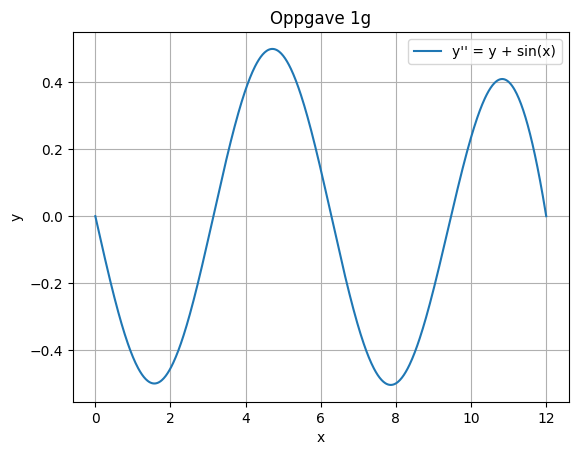

In [248]:
x_init_g = 0
x_end_g = 12
y_boundaries_g=(0,0)
b0=3
b1=2
tol_gh= 1e-7

result_g = BVP_solver(diff_func_1g,x_init_g,x_end_g,y_boundaries_g,b0,b1, tol=tol_gh)


plt.figure("BVP solution 1g")
plt.plot(result_g[0],result_g[1][:,0], label = "y'' = y + sin(x)")
plt.title("Oppgave 1g")
plt.grid()
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

Over er plottet av den numeriske løste løsningen av differensialligningen $\frac{\partial^2y}{\partial x^2} = y + sin(x)$. Løsninen passer i grensebetingelsene. Utifra differensialligningen kunne man forvente at løsningen kom til å ha et exponesial ledd og et harmonisk ledd. Det passer bra med det vi ser av løsningen der den ihvertfall har et harmonisk ledd, men også noe som kan tyde på et eksponesial ledd siden den viser en liten negativ vekst.

### 1h

In [249]:
def diff_func_1h(
        x : float,
        y : np.ndarray[np.float64]
    )  -> np.ndarray[np.float64]:

    out=np.zeros_like(y)

    out[0]=y[1]
    out[1]=y[0] + np.sin(x)
    
    return np.vstack(out)

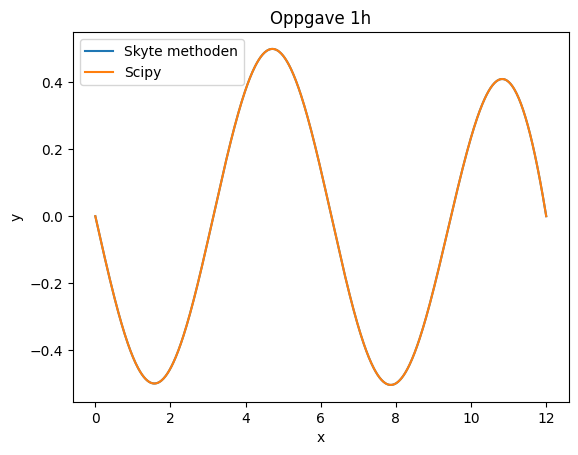

In [250]:
def y_bound(ya,yb):
    return np.array([ya[0],yb[0]])
x=np.linspace(x_init_g,x_end_g,10)
y_a = np.zeros((2, x.size))



res_a = solve_bvp(diff_func_1h,y_bound,x,y_a, tol =tol_gh)
plt.figure("BVP solution 1h")
x_plot = result_g[0]
y_plot_a = res_a.sol(x_plot)[0]

import matplotlib.pyplot as plt
plt.plot(x_plot, result_g[1][:,0], label="Skyte methoden")
plt.plot(x_plot, y_plot_a, label='Scipy')

plt.title("Oppgave 1h")
plt.legend()
plt.xlabel("x")
plt.ylabel("y")
plt.show()

Her er løsningen fra den egenimplementerte skyte metoden og solve_bvp plottet sammen. Kan se at løserne definitivt kommer fram til samme løsning, som er ønskelig.

C:\Users\godis\AppData\Local\Temp\ipykernel_29532\647559590.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


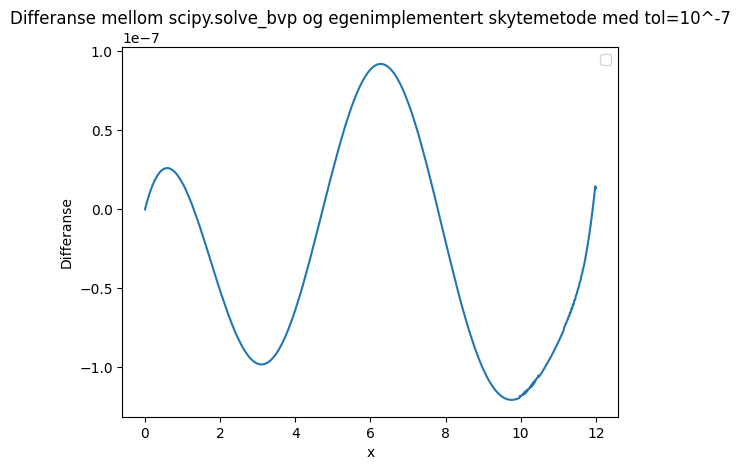

In [280]:
plt.plot(x_plot, result_g[1][:,0]-y_plot_a)
plt.title("Differanse mellom scipy.solve_bvp og egenimplementert skytemetode med tol=10^-7")
plt.legend()
plt.xlabel("x")
plt.ylabel("Differanse")
plt.show()

Over er plottet for differansen mellom egenimplmentert skytemetode og scipy bibloteket sitt solve_bvp. Det første å bemerke seg er at er i samme størrelse skala som toleransen. Dette passer bra med resultatet i oppgave 1d, der vi fant ut at feilen i skytemetoden er nært linær (polynomisk) med toleransen. Siden toleransen er satt til det samme for solve_bvp bør feilen dennes også maks være på størrelses skala med toleransen, dermed vil differansen dem i mellom også være i den størrelsesskalaen. Grafen viser også en fordel solve_bvp har over skytemetoden. I grafen kan en se at differansen øker med høyere x_verdi. Dette kommer av at rungekutta metoden for å løse initialverdi problemer løser fra x_init til x_end, som gjør at rungekutta akumulerer feil når den jobber seg mot x_end, slik at den gir mer feil nære x_end. Derimot helt nære x_end vil feilen bli mindre igjen ettersom den har løsningen i x_end og prøver å minimerer for feilen i x_end. 

## Oppgave 2

### 2a

In [252]:

def toRealVector(
    complexMatrix : np.ndarray[tuple[int,int], np.dtype[np.complex128]]
    )->np.ndarray[tuple[int], np.dtype[np.float64]]:
    """Convert complex 2x2 matrix to real 1x8 array, return array."""

    return np.concatenate((complexMatrix.real.flatten(), complexMatrix.imag.flatten()))



def toComplexMatrix(
    realVector : np.ndarray[tuple[int], np.dtype[np.float64]]
    )->np.ndarray[tuple[int, int], np.dtype[np.complex128]]:
    """Convert real 1x8 vector to complex 2x2 matrix, return matrix."""

    return (realVector[:4]+realVector[4:]*1j).reshape((2,2))


def test2a() -> None:
    """Tests if toRealVector and toComplexMatrix are inverse functions."""

    for i in range(999):
        A = np.random.random(8)
        B = toRealVector(toComplexMatrix(A))
        assert not np.any(A-B)
    print("test2a passed")

test2a()

test2a passed


Tester ved å definere en matrise og transformere fram og tilbake med de egen definerte funksjonene.

In [253]:
test2a()

test2a passed


Ser at resultatet blir slik vi ønsker det.

### 2b

In [254]:

def toComponentVectors(
    vec : np.ndarray[tuple[int], np.dtype[np.float64]]
    )->tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Split 1x8 array in four arrays, return tuple of the arrays."""

    return vec[:8], vec[8:16], vec[16:24], vec[24:32]


def toLongVector(
    m1 : np.ndarray,
    m2 : np.ndarray,
    m3 : np.ndarray,
    m4 : np.ndarray
    ) -> np.ndarray:
    """Concatenate 4 arrays, return concatenated array"""

    return np.concatenate((m1, m2, m3, m4))

def test2b() -> None:
    """Tests if toLongVector and toComponentVector are inverse."""
    for i in range(999):
        A = np.random.random(32)
        B = toComponentVectors(A)
        C = toLongVector(B[0],B[1],B[2],B[3])
        assert not np.any(A - C)
    print("test2b passed")


Tester disse funksjonene og.

In [255]:
test2b()

test2b passed


Ser at resultatet blir slik vi ønsker.

### 2c

In [256]:
def to_32_component_vector(
    gamma : np.ndarray[tuple[int, int], np.dtype[np.complex128]],
    gammaTilde : np.ndarray[tuple[int, int], np.dtype[np.complex128]],
    omega : np.ndarray[tuple[int, int], np.dtype[np.complex128]],
    omegaTilde : np.ndarray[tuple[int, int], np.dtype[np.complex128]]
    )->np.ndarray[int, np.dtype[np.float64]]:
    """Convert 4 complex matrices to real array of length 32."""

    return toLongVector(
        toRealVector(gamma),
        toRealVector(gammaTilde),
        toRealVector(omega),
        toRealVector(omegaTilde))
        
def to_2D_matrices(
    vec : np.ndarray[tuple[int], np.dtype[np.float64]]
    ) -> tuple[
        np.ndarray[tuple[int, int], np.dtype[np.complex128]],
        np.ndarray[tuple[int, int], np.dtype[np.complex128]],
        np.ndarray[tuple[int, int], np.dtype[np.complex128]],
        np.ndarray[tuple[int, int], np.dtype[np.complex128]]
    ]:
    """Convert real array of lenght 32 to 4 comples matrices."""

    m1, m2, m3, m4 = toComponentVectors(vec)
    return toComplexMatrix(m1),toComplexMatrix(m2),toComplexMatrix(m3),toComplexMatrix(m4)

def test2c():
    for i in range(999):
        A = np.random(32)
        B = to_32_component_vector(toComplexMatrix(A))
        assert not np.any(A - B)
    print("test2c passed")
test2c()

Transformerer fra blokk-matrisene til vektor ved å først transformere blokkmatrisene til relle vektorer, og så sette de sammen til én lang vektor. For å transformere den andre veien deles vektoren inn i 4 vektorer, som siden transformeres til komplekse matriser. Løsningen av oppgaven forutsetter at $\vec{v}$ er på følgende form.

$$
\vec{v} =
\begin{pmatrix}
    \Re(\gamma_{11}) \cr \Re(\gamma_{12}) \cr \Re(\gamma_{21}) \cr \Re(\gamma_{22}) \cr \Im(\gamma_{11}) \cr \Im(\gamma_{12}) \cr \Im(\gamma_{21}) \cr \Im (\gamma_{22}) \cr
    \Re(\tilde\gamma_{11}) \cr \Re(\tilde\gamma_{12}) \cr \Re(\tilde\gamma_{21}) \cr \Re(\tilde\gamma_{22}) \cr \Im(\tilde\gamma_{11}) \cr \Im(\tilde\gamma_{12}) \cr \Im(\tilde\gamma_{21}) \cr \Im (\tilde\gamma_{22}) \cr
    \Re(\omega_{11}) \cr \Re(\omega_{12}) \cr \Re(\omega_{21}) \cr \Re(\omega_{22}) \cr \Im(\omega_{11}) \cr \Im(\omega_{12}) \cr \Im(\omega_{21}) \cr \Im (\omega_{22}) \cr
    \Re(\tilde\omega_{11}) \cr \Re(\tilde\omega_{12}) \cr \Re(\tilde\omega_{21}) \cr \Re(\tilde\omega_{22}) \cr \Im(\tilde\omega_{11}) \cr \Im(\tilde\omega_{12}) \cr \Im(\tilde\omega_{21}) \cr \Im (\tilde\omega_{22})
\end{pmatrix}
$$

Der $\Re$ betegner å ta realdelen av et tall, og $\Im$ betegner å ta imaginærdelen av tallet, gitt at to_32_component_vector tar inn matrisene $\gamma$, $\tilde\gamma$, $\omega$, og $\tilde\omega$ og at to_2D_matrices returnerer dem i den rekkefølgen.

Påfølgende oppgaver antar alltid at vektoren vil være skrevet på denne formen.

### 2d

In [257]:
def deriv(vec : np.ndarray[np.float64], epsilon : float):
    """Calculates the derivates of the vectorized Riccati matrices and their derivates.
    
    Parameters
    ----------
    vec : Real vectorized form of the Riccati matrices with their derivates.
    epsilon : dimensionless energy $(E - E_F)\Delta$
    Returns
    -------
    dx_vec : the derivative of vec.
    """
    gamma, gammaTilde, omega, omegaTilde = to_2D_matrices(vec)

    N = inv(I - gamma @ gammaTilde)
    N_tilde = inv(I - gammaTilde @ gamma)
    
    omegaDeriv = -2j * (epsilon + 0.01j)*gamma - 2 * omega @ N_tilde @ gammaTilde @ omega
    omegaTildeDeriv = -2j * (epsilon + 0.01j)*gammaTilde- 2 * omegaTilde @ N @ gamma @ omegaTilde

    return to_32_component_vector(omega, omegaTilde, omegaDeriv, omegaTildeDeriv)

<>:7: SyntaxWarning: invalid escape sequence '\D'
<>:7: SyntaxWarning: invalid escape sequence '\D'
C:\Users\godis\AppData\Local\Temp\ipykernel_29532\2822449299.py:7: SyntaxWarning: invalid escape sequence '\D'
  epsilon : dimensionless energy $(E - E_F)\Delta$


Definerer en funksjon som returnerer den deriverte av 32-komponet vektoren ved å transformere den til matriser, finne de deriverte av matrisene med differensial ligningene og så transformere de deriverte tilbake til en 32-komponet vektor.

### 2e

In [258]:
def get_fun(epsilon : float) -> callable:
    """Returns function compatible with solve_bvp with parameter epsilon.
    
    Parameters
    ----------
    epsilon : the unitless energy of the system.
    
    Returns
    -------
    fun : function calculating derivates compatible with solve_bvp"""
    def fun(
        x : np.ndarray, 
        matrix : np.ndarray[tuple[int, int], np.dtype[np.float64]]
        )->np.ndarray[tuple[int, int], np.dtype[np.float64]]:
        """Do derivate of all vectors in matrix, return derivative

        Parameters
        ----------
        x : argument required by solve_bvp, unused.
        matrix : (32, m) array containing the Riccati matrices and their derivates at m positions.

        Returns
        ----------
        dx_matrix : (32, m) array with the derivates of matrix.
        """
        return np.apply_along_axis(deriv, 0, matrix, epsilon)
    return fun

Definerer en funksjon som tar inn epsilon og returnerer en funksjon som er brukbar av solve_bvp. Funksjon som returneres bruker np.apply_along_axis for å evaluere deriv-funksjonen langs hele x-aksen. np.apply_along_axis bør ha lignende tidskompleksitet som np.einsum.

### 2f

In [259]:
def get_bc_normal_metal(l : float) -> callable:
    """Get bc function for normal metal compatible with solve_bvp with parameter l
    
    Parameters
    ----------
    l : the lenght of the interfacing metal.
    Returns
    -------
    bc : function calculating boundary condition residuals compatible with solve_bvp."""
    def bc(
        v_left : np.ndarray,
        v_right : np.ndarray,
        )->np.ndarray[int, np.dtype[np.float64]]:
        """Get residuals from left and right boundary conditions
        
        Parameters
        ----------
        v_left : Riccati matricies and their derivates at x = 0
        v_right : Riccati matrices and their derivates at x = l
        Returns
        -------
        residuals : residuals to optimize."""
        
        gamma_left, gamma_left_tilde, omega_left, omega_left_tilde = to_2D_matrices(v_left)
        gamma_right, gamma_right_tilde, omega_right, omega_right_tilde = to_2D_matrices(v_right)

        return to_32_component_vector(
            omega_left - 1/(3*l) * gamma_left,
            omega_left_tilde - 1/(3*l) * gamma_left_tilde,
            omega_right + 1/(3*l) * gamma_right,
            omega_right_tilde + 1/(3*l) * gamma_right_tilde)
    return bc

Gjør tilsvarende som oppgave 1e men for grensebetingelsene. Funksjonen som returneres tar in 32-komponent vektorene i grensen mellom midt metalet og metalene omkring den. Den transformerer vektoren til 4 2x2 matriser for og så bruke kvante tunnelering grensebetingelsen, med ricatti matrisene satt til null, for å regne venstre siden av grensebetingelsen. Det den returnerer skal ved riktig svar være lik null, som er slik form solve_bvp vil ha.

### 2g

In [260]:
l_g = 1
m_g = 101
x_g = np.linspace(0,l_g,m_g)
y_g = np.zeros((32,m_g))

results = dict()
for eps in range(3):
    results[eps] = solve_bvp(get_fun(eps), get_bc_normal_metal(l_g), x_g, y_g, verbose = 2)
    print(not results[eps].sol(x).any())


   Iteration    Max residual  Max BC residual  Total nodes    Nodes added  
       1          0.00e+00       0.00e+00          101             0       
Solved in 1 iterations, number of nodes 101. 
Maximum relative residual: 0.00e+00 
Maximum boundary residual: 0.00e+00
True
   Iteration    Max residual  Max BC residual  Total nodes    Nodes added  
       1          0.00e+00       0.00e+00          101             0       
Solved in 1 iterations, number of nodes 101. 
Maximum relative residual: 0.00e+00 
Maximum boundary residual: 0.00e+00
True
   Iteration    Max residual  Max BC residual  Total nodes    Nodes added  
       1          0.00e+00       0.00e+00          101             0       
Solved in 1 iterations, number of nodes 101. 
Maximum relative residual: 0.00e+00 
Maximum boundary residual: 0.00e+00
True


Her kjøres solve_bvp for $l=1$, $m=101$ og $\epsilon \in (0,1,2)$.

### 2h

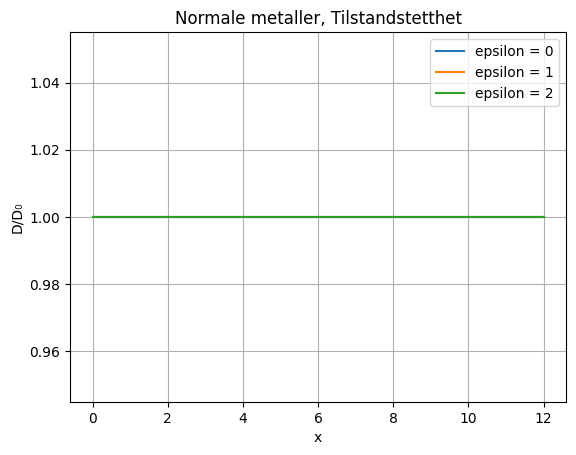

In [ ]:
def normDensity(vec : np.ndarray) -> float:
    """Returns the density D/D_0 as function of vectorized Riccati matrices"""
    gamma, gammaTilde, _, _ = to_2D_matrices(vec)
    
    N = inv(I - gamma @ gammaTilde)
    N_tilde = inv(I - gammaTilde @ gamma)

    return (np.trace(N) + np.trace(N_tilde)).real/2 - 1

for eps in range(3):
    density = np.apply_along_axis(normDensity, 0, results[eps].sol(x_g))
    plt.plot(x_g, density, label = f'epsilon = {eps}')

plt.xlabel('x')
plt.ylabel(u'D/D\u2080')
plt.grid()
plt.title("Normale metaller, Tilstandstetthet")
plt.legend()
plt.show()

Over er plottet for den normaliserte tilstandtettheten til midt metallet når den er mellom to andre normale metaller for normalisert energi 0,1 og 2. Kan se at den er helt konstant og overlappende for alle energiene. Dette er slik som forventet, ettersom når metallet er ved siden av to andre normale metallet er det ingenting som påvirker tilstandstettheten i metallet.

### 2i

In [262]:
def get_ricatti(l : float, epsilon : float, phi_L : float, phi_R :float):
        """Get the riccati matrices at the boundary of the interfacing metal.
        
        Paramenters
        -----------
        l :             length of the interfacing metal.
        epsilon :       normalized energy.
        phi_L :         the phase of the superconducting metal to the left of the interfacing metal.
        phi_R :         the phase of the superconducting metal to the right of the interfacing metal.

        Returns
        -------
        gamma_L :       Riccati gamma matrix for the superconducting metal to the left of the interfacing metal.
        gamma_L_tilde : Riccati gamma ~ matric for the superconducting metal to the left of the interfacing metal.
        gamma_R :       Riccati gamma matrix for the superconducting metal to the right of the interfacing metal.
        gamma_R_tilde : Riccati gamma ~ matrix for the superconducting metal to the right of the interfacing metal.
        """
        def theta(sigma, epsilon):
            return np.atanh(sigma/(epsilon + 0.01j))
        
        def s(sigma, epsilon):
            return np.sinh(theta(sigma, epsilon))
        
        def c(sigma, epsilon):
            return np.cosh(theta(sigma, epsilon))
        
        s_minus_c_minus = s(-1, epsilon)/(1 + c(-1, epsilon))
        s_plus_c_plus = s(1, epsilon)/(1 + c(1, epsilon))

        gamma_L = np.asarray(([0, s_plus_c_plus], [s_minus_c_minus, 0])) * np.exp(1j * phi_L)
        gamma_L_tilde = np.asarray(([0, s_minus_c_minus], [s_plus_c_plus, 0])) * np.exp(-1j * phi_L)
        gamma_R = np.asarray(([0, s_plus_c_plus], [s_minus_c_minus, 0])) * np.exp(1j * phi_R)
        gamma_R_tilde = np.asarray(([0, s_minus_c_minus], [s_plus_c_plus, 0])) * np.exp(-1j * phi_R)

        return gamma_L, gamma_L_tilde, gamma_R, gamma_R_tilde


def get_bc_superconductor(
        l : float,
        epsilon : float,
        phi_L : float,
        phi_R : float
        )->callable:
    """Get bc function for superconductor compatible with solve_bvp with parameters
    
    Parameters
    ----------
    l :             length of the interfacing metal.
    epsilon :       normalized energy.
    phi_L :         the phase of the superconducting metal to the left of the interfacing metal.
    phi_R :         the phase of the superconducting metal to the right of the interfacing metal.

    Returns
    -------
    bc : function calculating boundary condition residuals compatible with solve_bvp."""
    
    gamma_L, gamma_L_tilde, gamma_R, gamma_R_tilde = get_ricatti(l, epsilon, phi_L, phi_R)

    def bc(
        v_left : np.ndarray[int, np.dtype[np.float64]],
        v_right : np.ndarray[int, np.dtype[np.float64]],
        )->np.ndarray[int, np.dtype[np.float64]]:
        """Get residuals from left and right boundary conditions
        
        Parameters
        ----------
        v_left : Riccati matricies and their derivates at x = 0
        v_right : Riccati matrices and their derivates at x = l
        Returns
        -------
        residuals : residuals to optimize."""

        gamma_left, gamma_left_tilde, omega_left, omega_left_tilde = to_2D_matrices(v_left)
        gamma_right, gamma_right_tilde, omega_right, omega_right_tilde = to_2D_matrices(v_right)

        N_L = inv(I - gamma_L @ gamma_L_tilde)
        N_L_tilde = inv(I - gamma_L_tilde @ gamma_L)
        N_R = inv(I - gamma_R @ gamma_R_tilde)
        N_R_tilde = inv(I - gamma_R_tilde @ gamma_R)

        return to_32_component_vector(
            omega_left + 1/(3*l) * (I - gamma_left @ gamma_L_tilde) @ N_L @ (gamma_L - gamma_left),
            omega_left_tilde + 1/(3*l) * (I - gamma_left_tilde @ gamma_L) @ N_L_tilde @ (gamma_L_tilde - gamma_left_tilde),
            omega_right - 1/(3*l) * (I - gamma_right @ gamma_R_tilde) @ N_R @ (gamma_R - gamma_right),
            omega_right_tilde - 1/(3*l) * (I - gamma_right_tilde @ gamma_R) @ N_R_tilde @ (gamma_R_tilde - gamma_right_tilde)
            )
    
    return bc

Her defineres ricattimatrisene for en superleder, og så brukes riccatimatrisene til å lage grensebetingelsene til usadelligningen for midt metallet.

### 2j

   Iteration    Max residual  Max BC residual  Total nodes    Nodes added  
       1          1.00e-05       9.77e-07          101             0       
Solved in 1 iterations, number of nodes 101. 
Maximum relative residual: 1.00e-05 
Maximum boundary residual: 9.77e-07


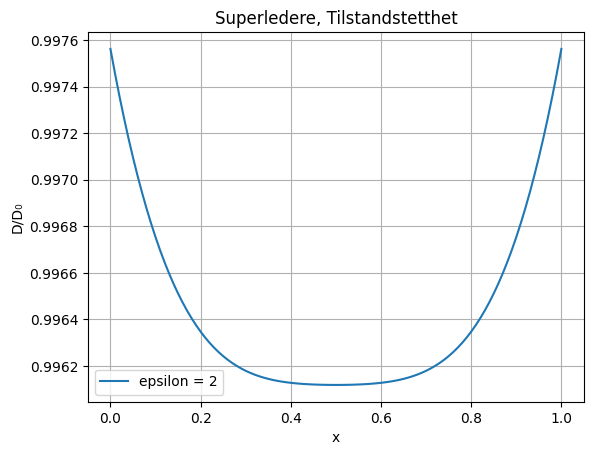

In [263]:
l = 1
m = 101
x = np.linspace(0,l,m)
y = np.zeros((32,m))
epsilon = 2
phi_L = phi_R = 0
res = solve_bvp(get_fun(epsilon), get_bc_superconductor(l, epsilon, phi_L, phi_R), x, y, verbose = 2)

density = np.apply_along_axis(normDensity, 0, res.sol(x))
plt.plot(x, density, label = f'epsilon = {epsilon}')
plt.xlabel('x')
plt.ylabel('D/D\u2080')
plt.grid()
plt.title("Superledere, Tilstandstetthet")
plt.legend()
plt.show()

Over er plottet for den normaliserte tilstandtettheten til midt metallet når den er mellom to superledere med lik fase. Josephson effekten tilsier at metallet i midten mellom superlederne opplever et strøm avhengig av differansen mellom fasene til superlederne. Superlederne for denne utregningen har lik fase, som betyr at vi forventer null strøm. Dette passer med den numersike løseren, siden plottet er symetrisk og det vil indikerer null strøm. Vi kan og se at for denne 

### 2k

l = 2: 100%|██████████| 101/101 [01:04<00:00,  1.56it/s]


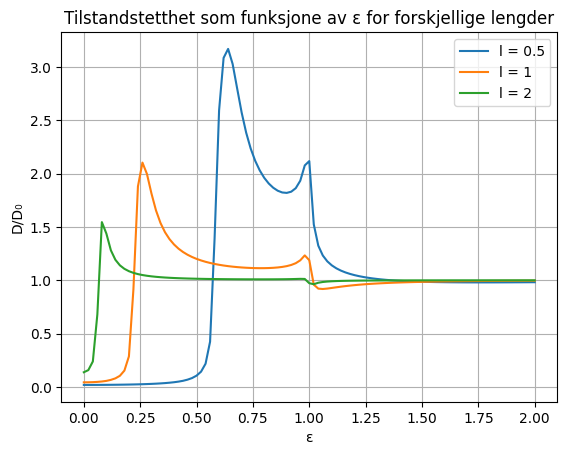

In [264]:
results_per_l = []
for l in [0.5, 1, 2]:
    results = []
    m = 101
    x = np.linspace(0,l,m)
    y = np.zeros((32,m))
    epsilon_arr = np.linspace(2, 0, m)
    phi_L = phi_R = 0

    for i in trange(m, desc = f"l = {l}"):
        res= solve_bvp(get_fun(epsilon_arr[i]), get_bc_superconductor(l, epsilon_arr[i], phi_L, phi_R), x, y)
        results.append(res)
        y = res.sol(x)
    plt.plot(epsilon_arr, [np.apply_along_axis(normDensity, 0, res.sol(l/2)) for res in results], label = f"l = {l}")
    results_per_l.append(results)
plt.legend()
plt.title("Tilstandstetthet som funksjone av \u03B5 for forskjellige lengder")
plt.ylabel('D/D\u2080')
plt.xlabel('\u03B5')
plt.grid()
plt.show()

Over er plottet for tilstandstettheten over den dimensjonløse energien $\epsilon$ for $l$ lik 0.5, 1 og 2. Kan se at ved lengre lengder blir minigapet smalere og kantene lavere. At det ved lengre lengder er smalerer og har lavere kanter virker intuitivt fordi at når metallet er større vil superlederne ha mindre innflytelse over metallet i midten, slik at superleder egenskapene det normale metallet i midten vil oppleve er svakere.

### 2l

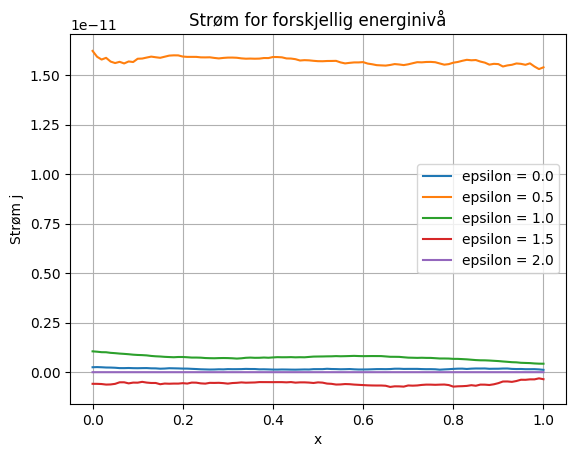

In [265]:
results_for_1 = results_per_l[1]

def current_density(vec : np.ndarray[tuple[int], np.dtype[np.float64]]) -> float:
    """Returns current density integrand as function of Riccati matrices.
    
    Paramenters
    -----------
    vec : (32,) array with Riccati matrices and their derivates at a given position and energy.

    Returns
    -------
    curr_density : the current density at given position.
    """

    gamma, gamma_tilde, omega, omega_tilde = to_2D_matrices(vec)

    N = inv(I - gamma @ gamma_tilde)
    N_tilde = inv (I - gamma @ gamma_tilde)

    dx_N = N @ (omega @ gamma_tilde + gamma @ omega_tilde) @ N
    dx_N_tilde = N_tilde @ (omega_tilde @ gamma + gamma_tilde @ omega) @ N_tilde

    g = np.block([[2*N-I, 2 * N @gamma], [-2*N_tilde@gamma_tilde, -2*N_tilde+I]])
    dx_g = 2* np.block([[dx_N, N @omega + dx_N @gamma], [-N_tilde @omega_tilde - dx_N_tilde @ gamma_tilde, -dx_N_tilde]])

    rho = np.asarray([[1,0,0,0],[0,1,0,0],[0,0,-1,0],[0,0,0,-1]])

    return np.trace(rho @ (g @ dx_g - dx_g @ g)).real


res_2 = results_for_1[0]
res_1_5 = results_for_1[m//4]
res_1 = results_for_1[m//2]
res_0_5 = results_for_1[3*m//4]
res_0 = results_for_1[-1]

x = np.linspace(0, 1, m)

for idx, res in enumerate((res_0, res_0_5, res_1, res_1_5, res_2)):
    
    plt.plot(x, np.apply_along_axis(current_density, 0, res.sol(x)), label = f"epsilon = {idx/2}")
plt.legend()
plt.title("Strøm for forskjellig energinivå")
plt.xlabel("x")
plt.ylabel("Strøm j")
plt.grid()
plt.show()

Over er strømmen plottet som funksjon av posisjon for flere energi nivå. Som forventet er alle nær konstante og nesten lik null. Det ser fra plottet ut som om det er en strøm for $\epsilon = 0.5$, men aksen er i størrelse skala $10^{-11}$ så det kan tilegnes numerisk feil i løseren. Strømmen er bevart som funksjon av posisjon da variasjonen også er av såpass liten skala at det bør kunne tilegnes numeriske feil. Toleransen brukt i solve_bvp $10^{-3}$ som er langt høyere en $10^{-11}$, så vi regner det som rimelig at numeriske feil i skalaen $10^{-11}$ kan oppstå.

### 2m

In [266]:
l = 1
m = 101
x = np.linspace(0,l,m)
y = np.zeros((32,m))
epsilon_arr = np.linspace(2, 0, m)
phi_L = 1
phi_R = 0

results = []
for i in trange(m, desc = f"l = {l}"):
    res= solve_bvp(get_fun(epsilon_arr[i]), get_bc_superconductor(l, epsilon_arr[i], phi_L, phi_R), x, y)
    results.append(res)
    y = res.sol(x)

l = 1: 100%|██████████| 101/101 [01:06<00:00,  1.53it/s]


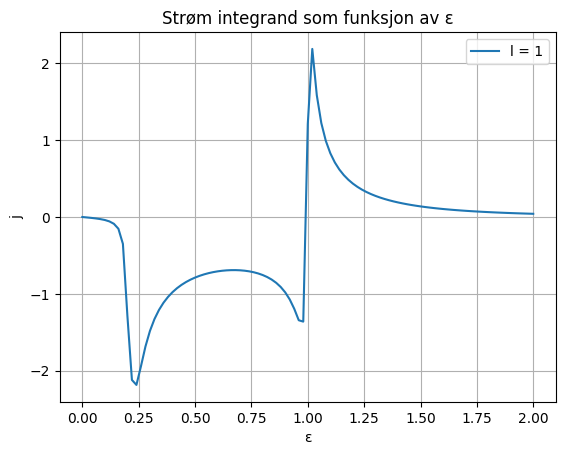

In [267]:
plt.plot(epsilon_arr, [np.apply_along_axis(current_density, 0, res.sol(l/2)) for res in results], label = f"l = {l}")
plt.legend()
plt.title("Strøm integrand som funksjon av \u03B5")
plt.xlabel("\u03B5")
plt.ylabel("j")
plt.grid()
plt.show()

Over er plottet av strømintegranden som funksjon av energinivå. I motsetning til plottet i oppgave 2l kan vi her observere at for visse energinivå er det en strøm. Videre kan en sammenligne plottet over med plottet for tilstandstettheten. Hvis en sammenligner dette plottet med plottet i oppgave 2k med samme $l$, så matcher strømmen for et energinivå bra med tilstandstetteheten for sammen energinivå. Dette matcher bra med fysikken for normale stoffer der at høyere tilstandstetteheten åpner for mer bevegelse av elektronene innenfor et energi nivå, derav mer strøm. Interesant å merke seg er at all strømmen i negativ retning befinner seg i energinivå som ville vært i minigapet til superlederen men som ikke er i minigapet vi kan observere for det normalemetalet i midten. ("Synse advarsel") Dette kan tyde på at det ikke vil være cooperpar i det normale metallet, men at strømmen den opplever kommer fra cooperpar i superlederne som beholder samme energinivå inne i det normale metallet. I tillegg så kan man observere på grafen en strøm i andre retningen utenfor minigapet til superlederen. Vi har ingen formening om hva dette er i realiteten men kan synse om at det kanskje er en slags motreaksjon som dannes av at det går en strøm inne i metallet uten et potensial. 

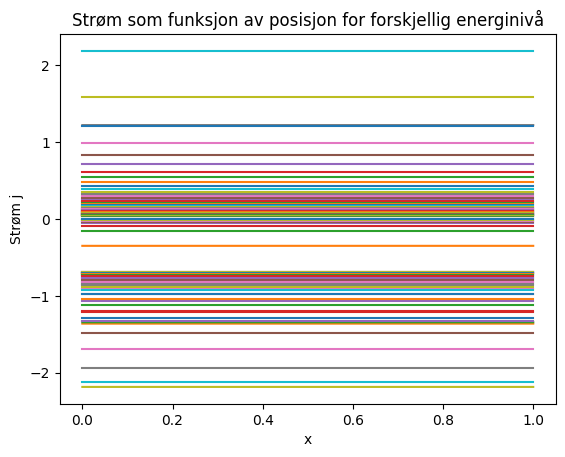

In [268]:
for idx, res in enumerate(results):
    plt.plot(x , np.apply_along_axis(current_density, 0, res.sol(x)), label = f"epsilon = {epsilon_arr[i]}")
plt.title("Strøm som funksjon av posisjon for forskjellig energinivå")
plt.xlabel("x")
plt.ylabel("Strøm j")
plt.show()


Dette er tilsvarende graf som i oppgave 2l, men med en faseforskjell. Denne har vi kun inkludert for å se at i dette tilfellet vil også strømmen være bevart som en funksjon av posisjon. Her kan en og se at strømmen for mange energinivå er ulik null, som er annerledes enn i oppgave 2l, for ingen faseforskjell. I tillegg bekrefter denne grafen til en hvis grad at variasjonen i oppgave 2l var på grunn av numeriske feil, siden linjene i denne grafen er helt rette.

### 2n

In [269]:
n = 10
m = 101

l = 1
x = np.linspace(0,l,m)
y = np.zeros((32,m))

phi_R = 0
phi_L_arr = np.linspace(0, 2*np.pi, n)
epsilon_arr = np.linspace(2, 0, m)

results_per_phi = []
for i in range(n):
    results = []
    for j in trange(m, desc = f"delta_phi = {phi_L_arr[i]}"):
        res= solve_bvp(get_fun(epsilon_arr[j]), get_bc_superconductor(l, epsilon_arr[j], phi_L_arr[i], phi_R), x, y)
        results.append(res)
        y = res.sol(x)
    results_per_phi.append(results)

delta_phi = 6.283185307179586: 100%|██████████| 101/101 [01:05<00:00,  1.55it/s]


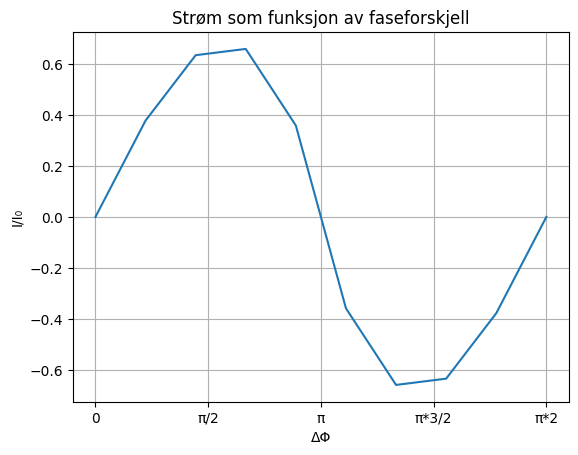

In [270]:
j_phi = np.array([[np.apply_along_axis(current_density, 0, res.sol(l/2)) for res in results] for results in results_per_phi])
I_phi = simpson(j_phi, epsilon_arr)

plt.plot(phi_L_arr, I_phi)
plt.title("Strøm som funksjon av faseforskjell")
plt.grid()
plt.xlabel("\u0394\u03A6")
plt.xticks([0,np.pi/2,np.pi,np.pi*6/4,2*np.pi],labels=[0,"\u03C0/2","\u03C0","\u03C0*3/2","\u03C0*2"])
plt.ylabel("I/I\u2080")
plt.show()

Over er plottet av den normaliserte strømmen som funksjon av faseforskjellen. Det første å bemerke seg er at den tar formen av en sinus funksjon. Det betyr blant annet at funksjonen er negativ symmetrisk rundt $\pi$, noe som gir mening ettersom superlederene er essensielt like, utenom faseforskjellen, så det burde kunne gå strøm begge veier. Vi finner et nullpunkt i endepunktene der fase forskjellen er null, slik vi har funnet i tidligere oppgaver. I tillegg finner vi et nullpunkt i $\pi$. Dette er også som forventet, siden $\pi$ og $-\pi$ er uadskillbare i bølgefunksjonen. Kort sagt så hvis det hadde fantes en strøm for faseforskjell lik $\pi$ hadde vi kunne med litt matematisk omdefinering funnet den samme strømmen andre veien, som er ufysisk. 